# Hypothesis And Inference

## Hypothesis Testing
Hypothesis testing in ststistics is a formal process used to determine whether the sample data provides enough evidence to specific research.

- **Null Hypothesis($H_0$)** : The dafault position i.e nothing special is happening. Example Coin is fair (P = 0.50)
- **Alternative Hypothesis($H_1$)** : What we want to check against or the effect we want to prove. Example Coin is not fair (P $\neq$ 0.5) 

In [2]:
# Import libraries

import math
import statistics as stats
import statsmodels as statm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Create function of Normal Probability Distributive Function 

def normal_pdf(x, mu=0, sigma=1):
    return math.exp(-(x - mu) ** 2 / 2 / sigma ** 2) / (math.sqrt(2 * math.pi) * sigma)

# Create function of Normal Cumulative Density Function

def normal_cdf(x, mu=0, sigma=1):
    return (1 + math.erf((x - mu) / math.sqrt(2) / sigma)) / 2

# Create function of Inverse of Normal Probability Distributive Function
# Find x where normal_cdf(x) approximate to p, using binary search

def inverse_normal_cdf(p, mu=0, sigma=1, tolerance=0.00001):
    if mu != 0 or sigma != 1:
        return mu + sigma * inverse_normal_cdf(p, tolerance=tolerance)
    low_z, hi_z = -10.0, 10.0
    while hi_z - low_z > tolerance:
        mid_z = (low_z + hi_z) / 2
        if normal_cdf(mid_z) < p:
            low_z = mid_z
        else:
            hi_z = mid_z
    return mid_z

### Flipping a Coin Example:

Before a local cricket tournament, the organisers want to check if the toss coin is fair.
- **$H_0$:** the coin is fair $\to$ probability of Heads p = 0.5
- **$H_1$:** the coin is not fair $\to$ p $\neq$ 0.5

We toss it n = 100 times and count the Heads (X). X is a **Binomial(n, p)** variable, which we can approximate with a **normal distribution**:
- mean = **$\mu$** = np
- standard deviation = **$\sigma$** = $\sqrt{np(1-p)}$

In [4]:
# Returns mu and sigma for a Binomial(n, p)

def normal_approximation_to_binomial(n, p):
    mu = n * p
    sigma = math.sqrt(n * p * (1 - p))
    return mu, sigma

mu_0, sigma_0 = normal_approximation_to_binomial(100, 0.5)
print("If the coin is fair: mean =", mu_0, ", standard deviation =", sigma_0)

If the coin is fair: mean = 50.0 , standard deviation = 5.0


In [5]:
# the normal cdf is the probability of being below a value

normal_probability_below = normal_cdf

# Above lo = not below lo
def normal_probability_above(lo, mu=0, sigma=1):
    return 1 - normal_cdf(lo, mu, sigma)

# Between = below hi, but not below lo
def normal_probability_between(lo, hi, mu=0, sigma=1):
    return normal_cdf(hi, mu, sigma) - normal_cdf(lo, mu, sigma)

# Outside = not between
def normal_probability_outside(lo, hi, mu=0, sigma=1):
    return 1 - normal_probability_between(lo, hi, mu, sigma)

print("P(X < 45)= ", round(normal_probability_below(45, mu_0, sigma_0), 3))
print("P(X > 55)= ", round(normal_probability_above(55, mu_0, sigma_0), 3))
print("P(45 < X < 55)= ", round(normal_probability_between(45, 55, mu_0, sigma_0), 3))
print("P(outside 45-55)= ", round(normal_probability_outside(45, 55, mu_0, sigma_0), 3))

P(X < 45)=  0.159
P(X > 55)=  0.159
P(45 < X < 55)=  0.683
P(outside 45-55)=  0.317


In [6]:
# Going backwards, finding the bounds
# Between which two values will X fall 95% of the time (if the coin is fair)

# Returns z such that P(Z <= z) = probability
def normal_upper_bound(probability, mu=0, sigma=1):
    return inverse_normal_cdf(probability, mu, sigma)

# Returns z such that P(Z >= z) = probability
def normal_lower_bound(probability, mu=0, sigma=1):
    return inverse_normal_cdf(1 - probability, mu, sigma)

# Returns the bounds (centred on the mean) that contain the given probability
def normal_two_sided_bounds(probability, mu=0, sigma=1):
    tail_probability = (1 - probability) / 2          # split the rest equally into two tails
    upper_bound = normal_lower_bound(tail_probability, mu, sigma)
    lower_bound = normal_upper_bound(tail_probability, mu, sigma)
    return lower_bound, upper_bound

lo, hi = normal_two_sided_bounds(0.95, mu_0, sigma_0)
print(f"95% of the time, a fair coin gives between {lo:.1f} and {hi:.1f} Heads in 100 tosses")

95% of the time, a fair coin gives between 40.2 and 59.8 Heads in 100 tosses


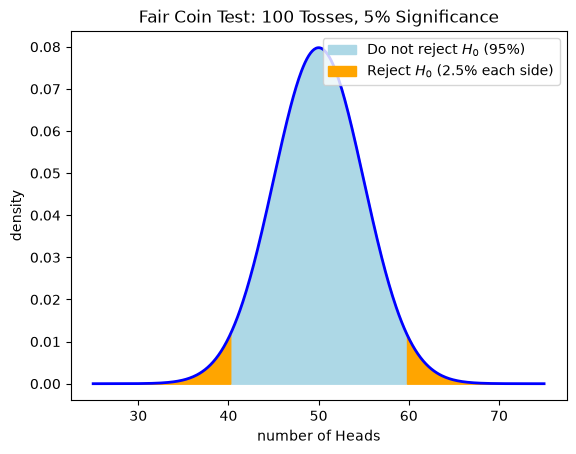

In [7]:
# Our test rule (at 5% significance)
# If Heads < 40.2 or Heads > 59.8, reject H₀ (the coin looks unfair).
# Otherwise, we cannot say the coin is unfair.

xs = [x / 10 for x in range(250, 751)]
ys = [normal_pdf(x, mu_0, sigma_0) for x in xs]

plt.plot(xs, ys, color='blue', linewidth=2)
plt.fill_between([x for x in xs if lo <= x <= hi],
                 [normal_pdf(x, mu_0, sigma_0) for x in xs if lo <= x <= hi],
                 color='lightblue', label=r"Do not reject $H_0$ (95%)")
plt.fill_between([x for x in xs if x <= lo],
                 [normal_pdf(x, mu_0, sigma_0) for x in xs if x <= lo],
                 color='orange', label=r"Reject $H_0$ (2.5% each side)")
plt.fill_between([x for x in xs if x >= hi],
                 [normal_pdf(x, mu_0, sigma_0) for x in xs if x >= hi],
                 color='orange')
plt.title("Fair Coin Test: 100 Tosses, 5% Significance")
plt.xlabel("number of Heads")
plt.ylabel("density")
plt.legend(loc="upper right")
plt.show()

### Types of Error:
In hypothesis testing, we make a decision about a claim (the null hypothesis) using sample data, and since we never observe the entire population, there is always a chance of making an incorrect decision. There are two main types of errors.

- A **Type I error** happens when we reject the null hypothesis even though it is actually true. In simple terms, it is a “false alarm”: we conclude that something is happening when it really isn’t, like a medical test indicating that a healthy person has a disease. The probability of making this error is called the **significance level**, denoted by $\alpha$ (alpha), and is usually set to 0.05 (5%).
- A **Type II error** happens when we fail to reject the null hypothesis even though it is actually false. This is a “missed detection”: we conclude that nothing is happening when something really is, like a test saying a sick person is healthy. The probability of this error is denoted by $\beta$ (beta), and 1 − $\beta$ is called the **power of the test**, which indicates how well the test detects a real effect.




In [8]:
# bounds assuming the coin is fair (p = 0.5)
lo, hi = normal_two_sided_bounds(0.95, mu_0, sigma_0)

# the real mean and sigma if p is actually 0.6
mu_1, sigma_1 = normal_approximation_to_binomial(100, 0.6)

# Type 2 error = X still falls inside our "don't reject" range
type_2_probability = normal_probability_between(lo, hi, mu_1, sigma_1)
power = 1 - type_2_probability
print(f"Power with 100 tosses = {power:.3f}")

Power with 100 tosses = 0.516


In [9]:
# Power of test

def power_of_test(n, true_p, significance=0.05):
    mu0, s0 = normal_approximation_to_binomial(n, 0.5)
    lo, hi = normal_two_sided_bounds(1 - significance, mu0, s0)
    mu1, s1 = normal_approximation_to_binomial(n, true_p)
    return 1 - normal_probability_between(lo, hi, mu1, s1)

for n in [50, 100, 200, 500, 1000]:
    print(f"n = {n:>4} tosses -> power = {power_of_test(n, 0.6):.3f}")

n =   50 tosses -> power = 0.289
n =  100 tosses -> power = 0.516
n =  200 tosses -> power = 0.812
n =  500 tosses -> power = 0.995
n = 1000 tosses -> power = 1.000


### One-sided test
Sometimes we only care about **one direction**. Example: the organisers only worry if the coin favours **Heads**.

- **$H_0$:** p $\le$ 0.5 (not biased towards Heads)
- **$H_1$:** p > 0.5

In [10]:
hi_one_sided = normal_upper_bound(0.95, mu_0, sigma_0)
print(f"One-sided rule: reject H₀ if Heads > {hi_one_sided:.1f}")

type_2_probability = normal_probability_below(hi_one_sided, mu_1, sigma_1)
print(f"Power of one-sided test (true p = 0.6) = {1 - type_2_probability:.3f}")

One-sided rule: reject H₀ if Heads > 58.2
Power of one-sided test (true p = 0.6) = 0.642


### p-values

A **p-value** is another way to do the same test.
- **p-value** = the probability of seeing a result at least as extreme as ours, assuming $H_0$ is true.
- **Small p-value** (less than 0.05) $\to$ our result would be very surprising if $H_0$ were true $\to$ **reject $H_0$**
- **Large p-value** $\to$ our result is quite normal under $H_0$ $\to$ **don't reject $H_0$**
- A p-value is not "the probability that H₀ is true". It only tells us how surprising the data is if $H_0$ were true.


In [17]:
def two_sided_p_value(x, mu=0, sigma=1):
    if x >= mu:
        # x is above the mean: the tail is everything above x
        return 2 * normal_probability_above(x, mu, sigma)
    else:
        # x is below the mean: the tail is everything below x
        return 2 * normal_probability_below(x, mu, sigma)

# We tossed the coin 100 times and got 60 Heads
p = two_sided_p_value(59.5, mu_0, sigma_0)
print(f"60 Heads -> p-value = {p:.3f} ->", "reject H_0" if p < 0.05 else "do NOT reject H_0")

# What if we got 62 Heads?
p = two_sided_p_value(61.5, mu_0, sigma_0)
print(f"62 Heads -> p-value = {p:.3f} ->", "reject H_0" if p < 0.05 else "do NOT reject H_0")

60 Heads -> p-value = 0.057 -> do NOT reject H_0
62 Heads -> p-value = 0.021 -> reject H_0


In [21]:
# Check with simulation
# Let's toss a fair coin 100 times, repeat this 200000 times.
# count how often we get a result as extreme as 60 (60 or more, or 40 or fewer)

np.random.seed(0)
experiments = 200000
extreme_count = 0

for _ in range(experiments):
    num_heads = sum(1 if np.random.random() < 0.5 else 0 for _ in range(100))
    if num_heads >= 60 or num_heads <= 40:
        extreme_count += 1

print("Simulated p-value ≈", extreme_count / experiments)

Simulated p-value ≈ 0.057465


In [23]:
# One_side p-value

upper_p_value = normal_probability_above
lower_p_value = normal_probability_below

# One-sided test (H₁: coin favours Heads)
for heads in [58, 59]:
    p = upper_p_value(heads - 0.5, mu_0, sigma_0)
    print(f"{heads} Heads -> one-sided p-value = {p:.3f} ->",
          "reject H_0" if p < 0.05 else "do NOT reject H_0")

58 Heads -> one-sided p-value = 0.067 -> do NOT reject H_0
59 Heads -> one-sided p-value = 0.045 -> reject H_0


### Confidence Intervals

Instead of a yes/no test, give a **range** of likely values for the unknown number.

#### Example: Tea or coffee
Take a example of 1000 random people in a city and 540 say they prefer tea.
- Our estimate: $\hat{p}$ = 540 / 1000 = 0.54 (54%)
- But this is only a sample. How sure can we be?

By the Central Limit Theorem, the estimate is roughly normal with standard deviation **$\sqrt{\frac{\hat{p}(1 - \hat{p})}{n}}$**.

In [24]:
def confidence_interval(successes, n, confidence=0.95):
    p_hat = successes / n
    sigma = math.sqrt(p_hat * (1 - p_hat) / n)
    return normal_two_sided_bounds(confidence, p_hat, sigma)

lo_ci, hi_ci = confidence_interval(540, 1000)
print(f"540 of 1000 prefer tea -> 95% confidence interval: {lo_ci:.3f} to {hi_ci:.3f}")
print("Is 0.5 (a 50-50 split) inside?", lo_ci <= 0.5 <= hi_ci)

540 of 1000 prefer tea -> 95% confidence interval: 0.509 to 0.571
Is 0.5 (a 50-50 split) inside? False


In [25]:
# What if only 520 said tea

lo_ci, hi_ci = confidence_interval(520, 1000)
print(f"520 of 1000 prefer tea -> 95% confidence interval: {lo_ci:.3f} to {hi_ci:.3f}")
print("Is 0.5 (a 50-50 split) inside?", lo_ci <= 0.5 <= hi_ci)

520 of 1000 prefer tea -> 95% confidence interval: 0.489 to 0.551
Is 0.5 (a 50-50 split) inside? True


### p-hacking 
p-hacking means testing many things or adjusting the data again and again, until something gives p < 0.05 and then reporting only that result.

#### Example
- With 5% significance, a fair coin will be wrongly called "unfair" 5% of the time. That is how the test is designed! Let's prove it: run 1000 experiments of 100 tosses each, all with a fair coin.
- A student tests whether 20 different "lucky" pen colours improve exam marks. Even if no colour has any effect, about 1 out of 20 will look "significant" by pure chance. Reporting "Blue pens improve marks (p < 0.05)!" would be P-hacking.

In [27]:
def run_experiment():
    """Toss a fair coin 100 times: True = Heads, False = Tails"""
    return [np.random.random() < 0.5 for _ in range(100)]

def reject_fairness(experiment):
    """Using our 5% significance bounds (40.2, 59.8)"""
    num_heads = sum(experiment)
    return num_heads < 40.2 or num_heads > 59.8

np.random.seed(1)
experiments = [run_experiment() for _ in range(1000)]
num_rejections = sum(1 for e in experiments if reject_fairness(e))
print("Fair coin wrongly called 'unfair' in", num_rejections, "out of 1000 experiments")

Fair coin wrongly called 'unfair' in 58 out of 1000 experiments


### A/B Testing 

**A/B testing** is used by almost every website and app. Show version **A** to some users and version **B** to others (chosen randomly), then compare the results.

#### Example: an online sweets shop
The shop tests two button texts:
- **A:** "Buy Now"
- **B:** "Order Today – Free Delivery"
Each version is shown to 1000 visitors.

- Each version's click rate is roughly normal with standard deviation **$\sqrt{p(1 − p) / N)}$**.
- The **difference** ($p_B − p_A$) is also normal with standard deviation **$\sqrt{\sigma_A^2 + \sigma_B^2}$**.
- **$H_0$:** both buttons work equally well (difference = 0).

In [28]:
def estimated_parameters(N, n):
    """N = number of views, n = number of clicks"""
    p = n / N
    sigma = math.sqrt(p * (1 - p) / N)
    return p, sigma

def a_b_test_statistic(N_A, n_A, N_B, n_B):
    p_A, sigma_A = estimated_parameters(N_A, n_A)
    p_B, sigma_B = estimated_parameters(N_B, n_B)
    return (p_B - p_A) / math.sqrt(sigma_A ** 2 + sigma_B ** 2)

# Case 1: A gets 100 clicks, B gets 120 clicks (out of 1000 each)
z = a_b_test_statistic(1000, 100, 1000, 120)
p = two_sided_p_value(z)
print(f"Case 1 (10% vs 12%): z = {z:.2f}, p-value = {p:.3f} ->",
      "B is better!" if p < 0.05 else "no clear difference")

# Case 2: A gets 100 clicks, B gets 150 clicks
z = a_b_test_statistic(1000, 100, 1000, 150)
p = two_sided_p_value(z)
print(f"Case 2 (10% vs 15%): z = {z:.2f}, p-value = {p:.4f} ->",
      "B is better!" if p < 0.05 else "no clear difference")

Case 1 (10% vs 12%): z = 1.43, p-value = 0.153 -> no clear difference
Case 2 (10% vs 15%): z = 3.39, p-value = 0.0007 -> B is better!


### Bayesian Inference

Everything so far is called the classical (frequentist) approach: we make statements about tests "if $H_0$ were true, data this extreme would happen only 3% of the time."

**Bayesian inference** is a different way of thinking:
- Start with a prior: your belief about the unknown value **before** seeing data.
- Collect data.
- Use Bayes's Theorem to update your belief $\to$ this gives the **posterior**.

Now we can make statements about the value itself, like "there is a 90% chance that p is between 0.6 and 0.8."

#### The Beta distribution
When the unknown value is a **probability** (between 0 and 1), we usually use a **Beta($\alpha$, $\beta$)** distribution as the prior.
- Its centre is at **$\alpha \div (\alpha + \beta)$**.
- **Bigger $\alpha$ and $\beta$ $\to$ narrower curve** (a stronger belief).

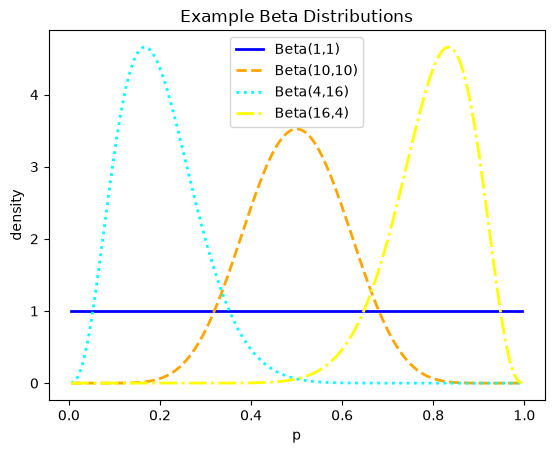

In [29]:
def B(alpha, beta):
    """A normalising constant so that the total probability is 1"""
    return math.gamma(alpha) * math.gamma(beta) / math.gamma(alpha + beta)

def beta_pdf(x, alpha, beta):
    if x <= 0 or x >= 1:          # no weight outside (0, 1)
        return 0
    return x ** (alpha - 1) * (1 - x) ** (beta - 1) / B(alpha, beta)

xs = [x / 200 for x in range(1, 200)]
for (a, b), color, style in [((1, 1), 'blue', "-"), ((10, 10), 'orange', "--"),
                             ((4, 16), 'aqua', ":"), ((16, 4), 'yellow', "-.")]:
    plt.plot(xs, [beta_pdf(x, a, b) for x in xs], style, color=color, linewidth=2,
             label=f"Beta({a},{b})")
plt.title("Example Beta Distributions")
plt.xlabel("p")
plt.ylabel("density")
plt.legend()
plt.show()

| Beta | Centre | Meaning as a belief |
|---|---|---|
| Beta(1, 1) | 0.5 | "I have no idea." Every value is equally likely (flat line) |
| Beta(10, 10) | 0.5 | "Probably around 50%" |
| Beta(4, 16) | 0.2 | "Probably low, around 20%" |
| Beta(16, 4) | 0.8 | "Probably high, around 80%" |

#### The magic update rule 
If the prior is **Beta($\alpha$, $\beta$)** and we observe **h successes** and **t failures**, the posterior is simply:

$$ Beta(\alpha + h, \beta + t) $$

(This works because the Beta is the **conjugate prior** of the Binomial: a Beta prior always gives a Beta posterior.)

#### Example: a new pani puri stall 
A new stall wants to know **p** = the share of customers who **love** its pani puri. Of the first **10 customers**, **7 loved it** and 3 didn't.

Three people start with different beliefs:
| Person | Prior belief | Prior | Posterior (after 7(yes), 3(No) ) |
|---|---|---|---|
| **Neutral friend** | "No idea" | Beta(1, 1) | Beta(8, 4) |
| **Doubtful uncle** | "Probably 50-50" | Beta(20, 20) | Beta(27, 23) |
| **Proud owner** | "Surely about 80% love it!" | Beta(16, 4) | Beta(23, 7) |

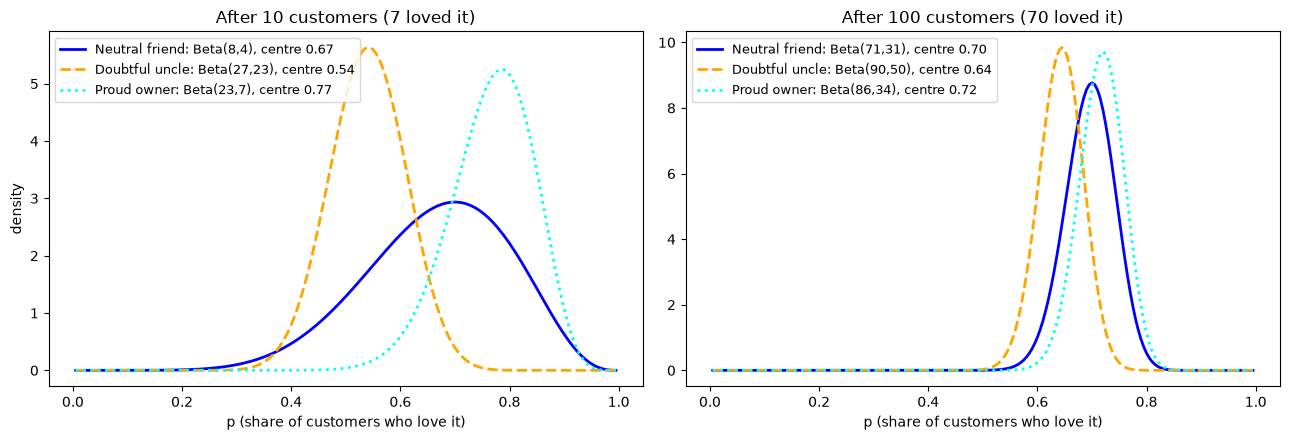

In [30]:
def beta_mean(alpha, beta):
    return alpha / (alpha + beta)

priors = {"Neutral friend": (1, 1), "Doubtful uncle": (20, 20), "Proud owner": (16, 4)}
colors = ['blue', 'orange', 'aqua']
styles = ["-", "--", ":"]

def plot_posteriors(loved, not_loved, ax):
    for (name, (a, b)), color, style in zip(priors.items(), colors, styles):
        post_a, post_b = a + loved, b + not_loved
        ax.plot(xs, [beta_pdf(x, post_a, post_b) for x in xs], style, color=color, linewidth=2,
                label=f"{name}: Beta({post_a},{post_b}), centre {beta_mean(post_a, post_b):.2f}")
    ax.set_xlabel("p (share of customers who love it)")
    ax.legend(loc="upper left", fontsize=9)

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
plot_posteriors(7, 3, left)
left.set_title("After 10 customers (7 loved it)")
left.set_ylabel("density")
plot_posteriors(70, 30, right)
right.set_title("After 100 customers (70 loved it)")
plt.tight_layout()
plt.show()